In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

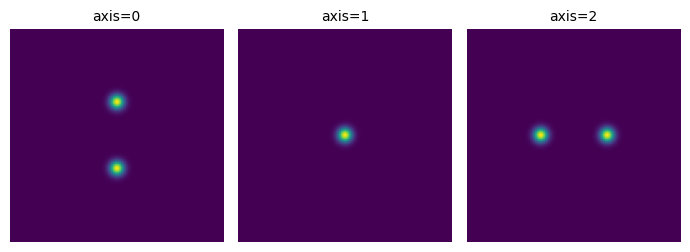

mass =  1.9999999999999993


In [17]:
L = 129   # grid size LxLxL
d = 3     # dimensons
sigma = 3 # Gaussian

z = utils.generate_centered_gaussian(L=L, d=d, sigma=sigma)
f = transforms.translate_3d(z, 0, -20, 0) + transforms.translate_3d(z, 0, 20, 0)

plots.orthogonal_2D_projection_plot(f)

print('mass = ', np.sum(f)) ### just for demonstration I add two Gaussians together each with mass = 1

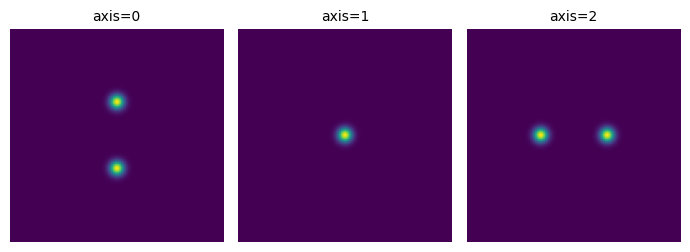

mass =  1.0000000000000002


In [18]:
F = signals.Signal(f, d=3).preprocess_signals()[0]

### NOTE: preprocess signal adds a spherical mask since distance is defined on ball, and normalizes mass to 1
### there is also an option to rescale so that mass = L, (in case overflow?)

### Signal and Transform class ALWAYS turn 2D and 3D arrays into a stack (if they are not already)
### e.g. if you pass in a single image it becomes 1xLxL so that operations can be applied to stacks

plots.orthogonal_2D_projection_plot(F)

print('mass = ', np.sum(F)) ### just for demonstration I add two Gaussians together each with mass = 1

In [19]:
### Then we can preform the various transforms on the preprocessed signal (single signal or a stack)
### by default, all sampling scales with L but we can control sampling in n_points, n_theta, n_phi as inputs

### The output tensor [should be] (numpy) z = phi, y = points, x = theta

t = time.time()
F_rt = transforms.Transform(F, d=3, apply_ramp=False).radon_transform()
print('Radon transform: ', time.time() - t)
t = time.time()
F_cdf = transforms.Transform(F, d=3, apply_ramp=False).cdf_transform()
print('  CDF transform: ', time.time() - t)
t = time.time()
F_icdf = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()
print(' ICDF transform: ', time.time() - t)

# ### when applying the ramp filter, the transform is signed, so we use
# F_rt = transforms.Transform(F, d=3, apply_ramp=True).radon_transform()
# F_cdf_p, F_cdf_n = transforms.Transform(F, d=3, apply_ramp=True).signed_cdf_transform()
# F_icdf_p, F_icdf_n = transforms.Transform(F, d=3, apply_ramp=True).signed_inverse_cdf_transform()

Radon transform:  1.7773103713989258
  CDF transform:  1.7859842777252197
 ICDF transform:  1.856956958770752


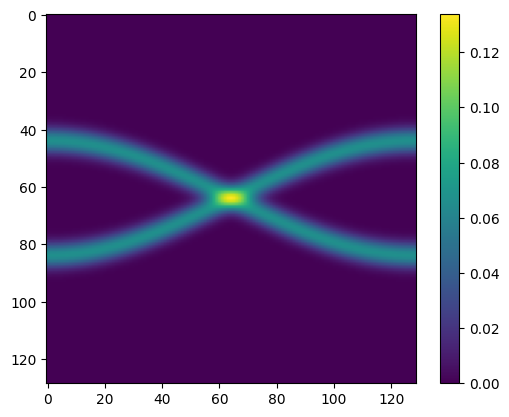

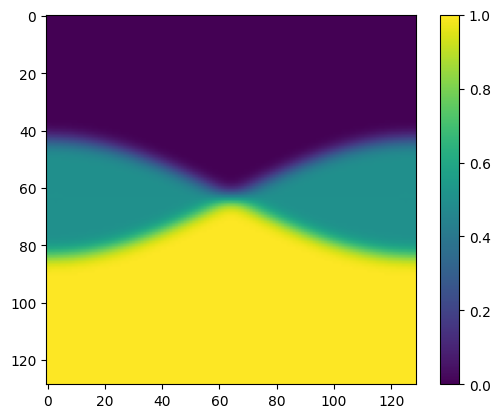

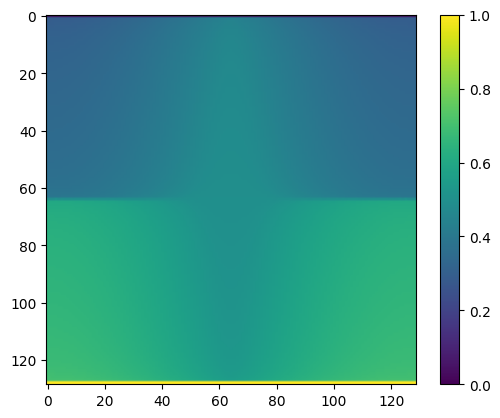

In [24]:
### For example, the transforms for theta when phi=0
plt.imshow(F_rt[0, 0, :, :])
plt.colorbar()
plt.show()
plt.imshow(F_cdf[0, 0, :, :])
plt.colorbar()
plt.show()
plt.imshow(F_icdf[0, 0, :, :])
plt.colorbar()
plt.show()